# Lepton-jet reconstruction efficiency: the coverage map of the control samples

Step 3 of [`lj_reco_efficiency.md`](lj_reco_efficiency.md) turns the data/simulation ratios of the
control samples into scale factors per lepton jet. The control samples do not reach every part of
the signal's phase space; where they do not, a lepton jet takes the scale factor of the nearest
measured bin, and every such case is recorded here, so that the group can assess them one by one.

What each measurement reaches (`systematics_study.LJ_COVERAGE`):

- **muon-type:** the $J/\psi \to \mu\mu$ probes from 30 to 300 GeV, with opening angles
  $\Delta R(\mu\mu)$ from 0.03 (below which the sideband subtraction does not close) to 0.4 and
  vertices out to $L_{xy}$ = 15 cm (notebooks 07 and 08); the DSA muons, measured with prompt
  muons (notebooks 09 and 10), which test them at any $L_{xy}$, since the muons of a boosted dark
  photon point back to the beam line;
- **egamma-type:** the photons of $Z \to \mu\mu\gamma$ from 30 to 120 GeV, converted and
  unconverted (notebook 08). A photon is one object and its conversion radius is not in the
  ntuples, so neither the opening angle nor the displacement is measured.

The signal side is step 1 (campaign `lj_reco_eff_v1`, simulation): the generator dark photons
matched to a selected lepton jet of their type, against their $p_T$ and $L_{xy}$ and the opening
angle of their leptons, for the 48 points per final state of the limit grid. No data are read.

In [1]:
import os, shutil, sys, tempfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LogNorm

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)

INPUT_DIR = sysstudy.eos_url(sysstudy.LJ_RECO_DIR)   # the merged outputs of lj_reco_eff_v1
OUTPUT_DIR = f"{INPUT_DIR}_results/coverage"         # figures and the table per point
WORK = Path(tempfile.mkdtemp(prefix="lj_coverage_"))  # removed at the end
# (final state, lepton-jet type): the egamma-type lepton jets exist in 2Mu2E only
CASES = [("2Mu2E", "muon-type"), ("4Mu", "muon-type"), ("2Mu2E", "egamma-type")]
COV = sysstudy.LJ_COVERAGE


def save(fig, name):
    """Write a figure into the working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK / f"{name}{suffix}", bbox_inches="tight")


inputs = sysstudy.lj_efficiency_inputs(INPUT_DIR)
# lifetimes are ranked on the full grid, so the limit grid is taken from it
LIMIT = set(sysstudy.limit_grid(study.signal_points())) & set(inputs)
grid = {fs: [s for s in sysstudy.ordered_points(list(inputs), fs) if s in LIMIT] for fs in ("2Mu2E", "4Mu")}
print({fs: len(p) for fs, p in grid.items()}, "points of the limit grid")

{'2Mu2E': 48, '4Mu': 48} points of the limit grid


## 1. Where the signal's lepton jets are

The matched dark photons of the limit grid in the plane of $L_{xy}$ and the opening angle of their
leptons, summed over the points as counts of simulated events (each point weighs by the size of
its sample, as in notebook 06), with the region the $J/\psi$ probes reach drawn for the muon-type
ones; and their $p_T$, with the measured ranges.

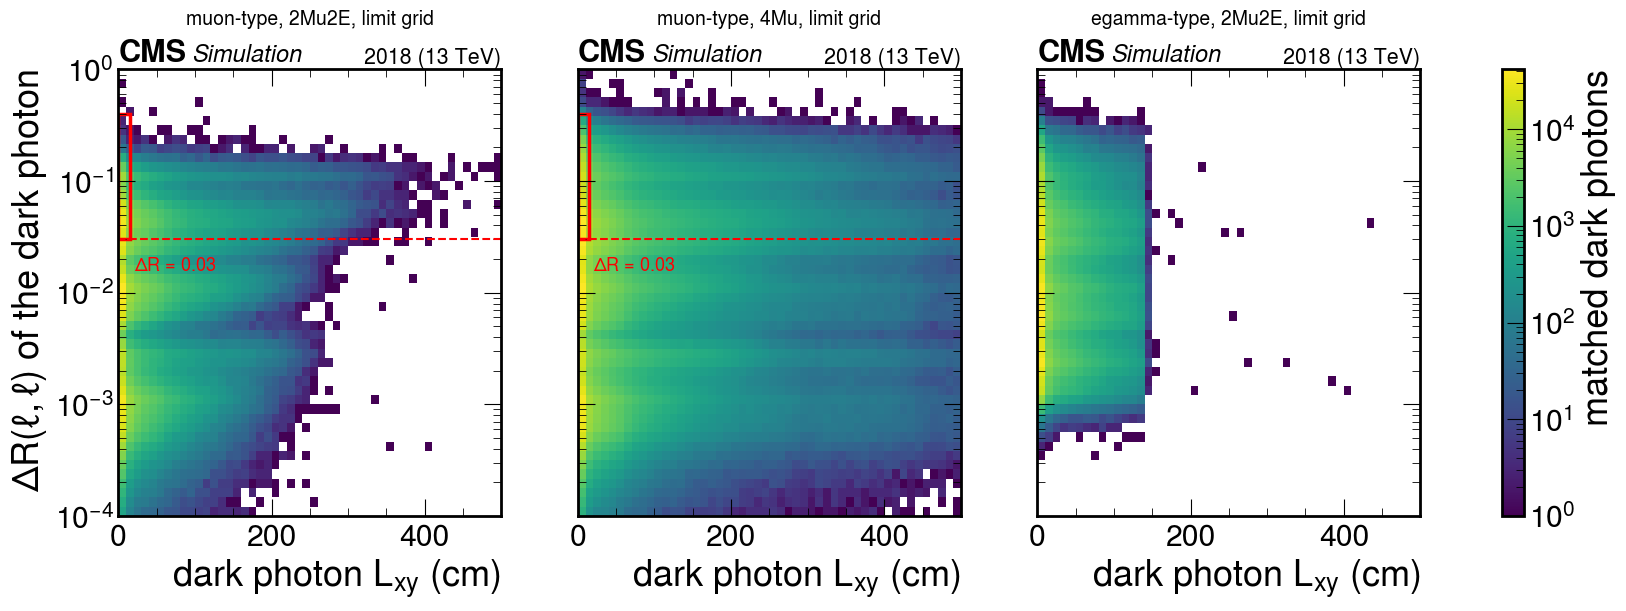

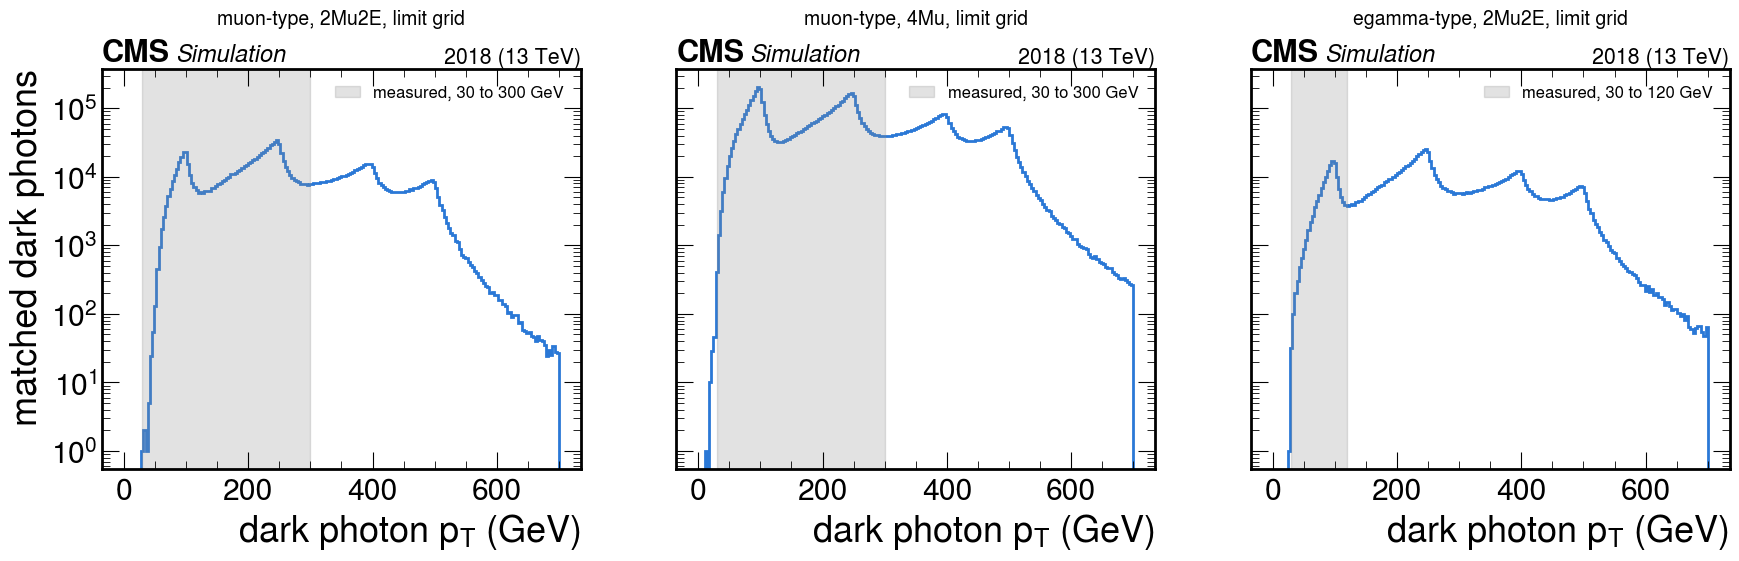

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.8), sharey=True)
for ax, (fs, lj_type) in zip(axes, CASES):
    num, _ = sysstudy.summed(inputs, grid[fs], lj_type, "map")
    mesh = ax.pcolormesh(num.axes[0].edges, num.axes[1].edges, np.where(num.values() > 0, num.values(), np.nan).T,
                         norm=LogNorm(), cmap="viridis")
    ax.set_yscale("log")
    ax.set_xlabel(r"dark photon $L_{xy}$ (cm)")
    ax.set_title(f"{lj_type}, {fs}, limit grid", fontsize=14, pad=32)   # above the CMS label
    if "dR" in COV[lj_type]:
        (x0, x1), (y0, y1) = COV[lj_type]["lxy"], COV[lj_type]["dR"]
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=2.5))
        ax.axhline(y0, color="red", linestyle="--", linewidth=1.5)
        ax.text(20, y0 * 0.7, r"$\Delta R$ = 0.03", color="red", fontsize=13, va="top")
axes[0].set_ylabel(r"$\Delta R(\ell, \ell)$ of the dark photon")
fig.colorbar(mesh, ax=list(axes), label="matched dark photons")
study.cms_label(axes)
save(fig, "coverage_lxy_dR")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(21, 5.2), sharey=True)
for ax, (fs, lj_type) in zip(axes, CASES):
    num, _ = sysstudy.summed(inputs, grid[fs], lj_type, "pt_high")
    ax.stairs(num.values(), num.axes[0].edges, color=study.BLUE, linewidth=2)
    lo, hi = COV[lj_type]["pt"]
    ax.axvspan(lo, hi, color=study.GRAY, alpha=0.25, label=f"measured, {lo:g} to {hi:g} GeV")
    ax.set_yscale("log")
    ax.set_xlabel(r"dark photon $p_T$ (GeV)")
    ax.set_title(f"{lj_type}, {fs}, limit grid", fontsize=14, pad=32)
    ax.legend(fontsize=12, loc="upper right")
study.cms_label(axes)
axes[0].set_ylabel("matched dark photons")
save(fig, "coverage_pt")
plt.show()

**Interpretation (run of 2026-11-24: `lj_reco_eff_v1`, the 48 points per final state of the limit
grid).** The muon-type lepton jets of the signal are far more collimated than the $J/\psi$ probes:
the opening angle of a dark photon's leptons is about $2m/p_T$, so for dark photons of 0.25 and
1.2 GeV the two muons are almost always closer than $\Delta R$ = 0.03, and only those of 5 GeV
fall in the $J/\psi$ range. That range also stops at $L_{xy}$ = 15 cm, while the dark photons decay
out to several meters. Their $p_T$ peaks near half the bound-state mass (100, 250, 400 and
500 GeV), so the $J/\psi$ range of 30 to 300 GeV holds the points up to 500 GeV, and the photon
range of 30 to 120 GeV only those of 200 GeV.

## 2. Per signal point: the lepton jets outside the measured ranges

For each point of the limit grid, the fraction of its matched dark photons outside each measured
range: $p_T$ above the highest measured bin, $\Delta R$ below 0.03 and, for the muon-type ones,
$L_{xy}$ beyond 15 cm and the fraction outside the $J/\psi$ measurement in the plane of $L_{xy}$
and $\Delta R$. Bins that hold a boundary are split in proportion to their width. The table goes to
EOS.

muon-type, 2Mu2E: median and largest fraction over the 48 points
        pt below  pt above  dR below  dR above  lxy below  lxy above  outside the J/psi plane
median       0.0     0.277     0.997       0.0        0.0      0.647                    0.999
max          0.0     0.888     1.000       0.0        0.0      0.898                    1.000
  median per m_Zd:
      pt below  pt above  dR below  dR above  lxy below  lxy above  outside the J/psi plane
m_zd                                                                                       
0.25       0.0     0.274     1.000       0.0        0.0      0.638                    1.000
1.20       0.0     0.344     0.997       0.0        0.0      0.681                    0.999
5.00       0.0     0.352     0.098       0.0        0.0      0.695                    0.783

muon-type, 4Mu: median and largest fraction over the 48 points
        pt below  pt above  dR below  dR above  lxy below  lxy above  outside the J/psi plane
median       0.0

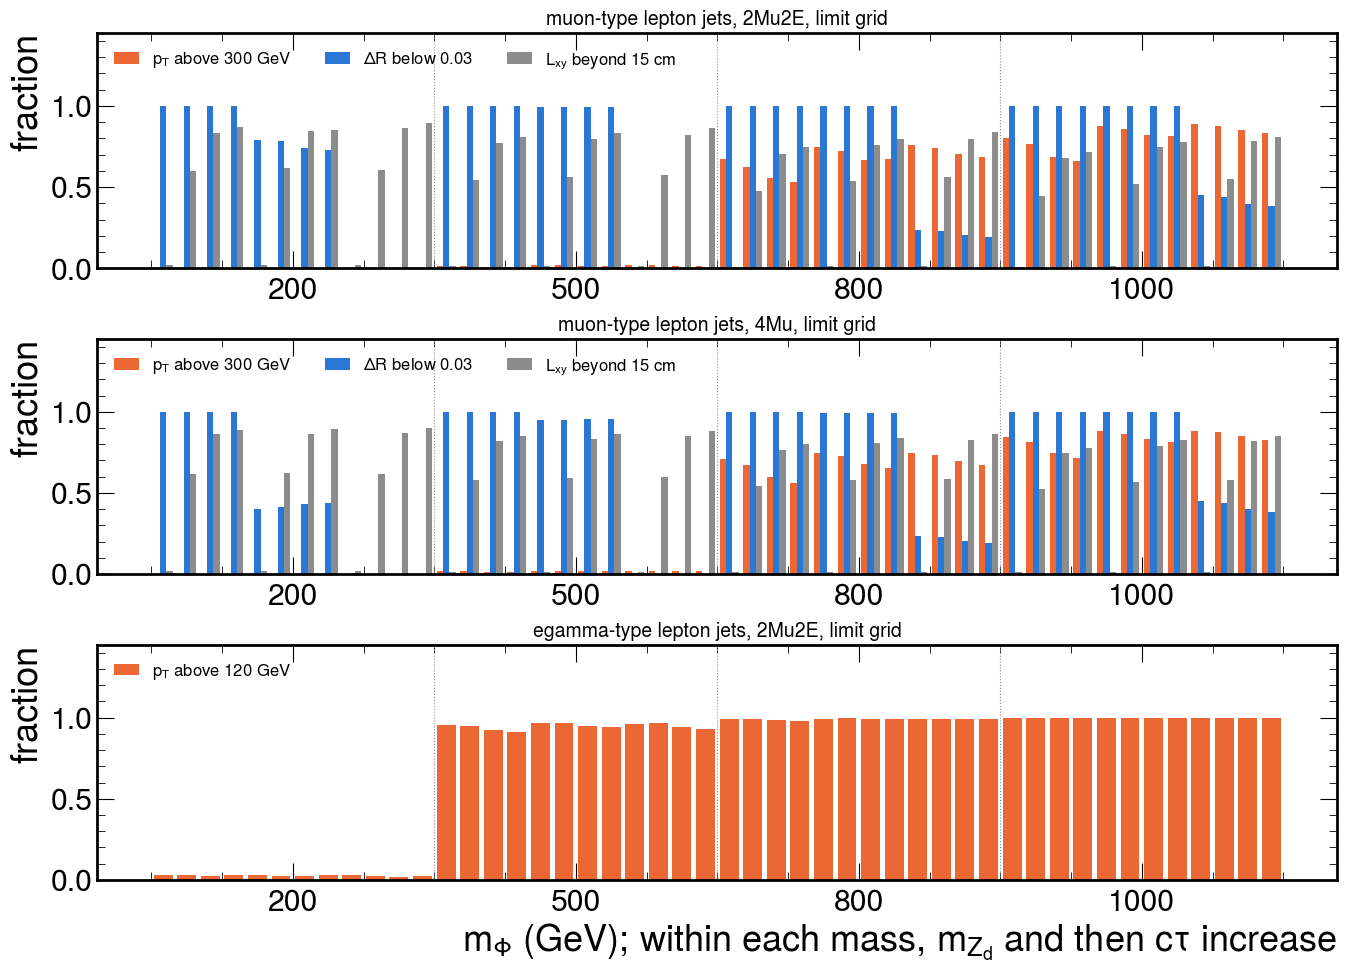

In [3]:
rows = []
for fs, lj_type in CASES:
    for s in grid[fs]:
        if lj_type in inputs[s]:
            p = study.parse_point(s)
            rows.append({"point": s, "final_state": fs, "lepton_jet": lj_type, "m_phi": p["m_phi"],
                         "m_zd": p["m_zd"], "ctau": p["ctau"], **sysstudy.coverage_fractions(inputs[s][lj_type], lj_type)})
table = pd.DataFrame(rows)
table.to_csv(WORK / "coverage.csv", index=False)
columns = [c for c in table.columns if c.endswith(("below", "above")) or c.startswith("outside")]
for (fs, lj_type), t in table.groupby(["final_state", "lepton_jet"], sort=False):
    keep = [c for c in columns if t[c].notna().any()]
    print(f"{lj_type}, {fs}: median and largest fraction over the {len(t)} points")
    print(t[keep].agg(["median", "max"]).round(3).to_string())
    print("  median per m_Zd:")
    print(t.groupby("m_zd")[keep].median().round(3).to_string())
    print()

SHOW = {"muon-type": [("pt above", r"$p_T$ above 300 GeV", study.ORANGE),
                      ("dR below", r"$\Delta R$ below 0.03", study.BLUE),
                      ("lxy above", r"$L_{xy}$ beyond 15 cm", study.GRAY)],
        "egamma-type": [("pt above", r"$p_T$ above 120 GeV", study.ORANGE)]}
fig, axes = plt.subplots(len(CASES), 1, figsize=(16, 11), sharey=True, gridspec_kw={"hspace": 0.3})
for ax, (fs, lj_type) in zip(axes, CASES):
    t = table[(table.final_state == fs) & (table.lepton_jet == lj_type)].set_index("point").loc[grid[fs]]
    x = np.arange(len(t))
    width = 0.8 / len(SHOW[lj_type])
    for i, (column, text, colour) in enumerate(SHOW[lj_type]):
        ax.bar(x + (i - (len(SHOW[lj_type]) - 1) / 2) * width, t[column], width=width, color=colour, label=text)
    ax.set_ylim(0, 1.45)
    ax.set_ylabel("fraction")
    ax.set_title(f"{lj_type} lepton jets, {fs}, limit grid", fontsize=14)
    ax.legend(ncol=3, fontsize=12, loc="upper left")
    sysstudy.mass_ticks(ax, grid[fs], label=ax is axes[-1])
save(fig, "coverage_per_point")
plt.show()

**Interpretation.** Muon-type lepton jets lie below $\Delta R$ = 0.03 in a median 99.7% (2Mu2E)
and 97% (4Mu) of the cases over the limit grid: all of them for 0.25 GeV dark photons, a median 10%
for those of 5 GeV. They lie beyond $L_{xy}$ = 15 cm in a median 65% and 68% of the cases (at most
90%), and above 300 GeV in 28% and 29% (up to 89% at 1000 GeV). Outside the $J/\psi$ measurement
in the plane of $L_{xy}$ and $\Delta R$ together lie a median 99.9% and 99.3%, and 78% and 80% for
the 5 GeV dark photons. Egamma-type lepton jets lie above 120 GeV in a median 97% of the cases, and
in 3% at 200 GeV. Nearly every lepton jet of the signal therefore lies outside the measured range in
at least one variable: the opening angle for the muon-type ones, the $p_T$ for the egamma-type
ones.

## 3. What the map gives

- **Where step 3 extrapolates.** Muon-type: below $\Delta R$ = 0.03 for nearly every point with
  dark photons of 0.25 and 1.2 GeV, beyond $L_{xy}$ = 15 cm for the PF and tracker muons (the DSA
  muons are measured with prompt muons), and above 300 GeV for the bound states of 800 and
  1000 GeV. Egamma-type: above 120 GeV for every point but those of 200 GeV, and in the
  displacement and the opening angle, which no sample measures.
- **The record.** The table on EOS (`coverage.csv`) gives, per point and lepton-jet type, the
  fraction of its lepton jets outside each range; these are the cases the group goes through one
  by one when the scale factors take the nearest measured bin.
- **Its limits.** The map uses the generator quantities of the dark photon ($p_T$, $L_{xy}$, the
  opening angle of its leptons), the variables in which the scale factors would be binned, and
  treats each separately except $L_{xy}$ and $\Delta R$, which step 1 records together.

In [4]:
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_eff_v1_results/coverage
